# 🛒 E-Commerce Customer Intelligence & Marketing Performance Analysis

**Author:** Bogart Caligonan
**Date:** October 2026
**Dataset:** UCI Online Retail II
**Tools:** Python · pandas · scikit-learn · matplotlib · seaborn

---

Every online store has a story hidden in its transactions: who buys, how often, which channels bring them in, and who quietly drifts away. In this project I set out to uncover that story, taking raw order data all the way to clear, actionable marketing recommendations.

## Table of Contents

1. [Environment Setup & Data Loading](#1)
2. [Data Cleaning & Preprocessing](#2)
3. [Exploratory Data Analysis (EDA)](#3)
4. [RFM Segmentation & K-Means Clustering](#4)
5. [Cohort Retention Analysis](#5)
6. [Marketing Channel Attribution](#6)
7. [Campaign A/B Test Analysis](#7)
8. [Customer Lifetime Value (CLV) Prediction](#8)
9. [Executive Summary & Recommendations](#9)

<a id="1"></a>
## 1. Environment Setup & Data Loading

Every analysis starts with data, so my first step was getting to know the **UCI Online Retail II** dataset (`online_retail_II.xlsx`). It holds every transaction from a UK-based online retailer between **December 2009 and December 2011**, split across two sheets. I loaded both sheets and combined them into a single DataFrame so I could follow the full two-year story in one place.

The data told me what customers bought, but not how they found the store or which campaign they saw. Because I wanted to answer those marketing questions too, I **engineered** two extra fields: a realistic acquisition channel and an A/B campaign variant for each customer. These power the channel attribution and A/B testing sections later on.

> **Dataset columns:** Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID, Country

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy import stats

plt.rcParams.update({
    'figure.figsize': (12, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
palette = ['#2563EB', '#10B981', '#F59E0B', '#EF4444', '#8B5CF6', '#EC4899']
sns.set_palette(palette)

print("✅ All libraries loaded successfully.")

✅ All libraries loaded successfully.


In [2]:
df_2009 = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2009-2010')
df_2010 = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2010-2011')
df_raw = pd.concat([df_2009, df_2010], ignore_index=True)

df_raw['Invoice'] = df_raw['Invoice'].astype(str)

print(f"✅ Loaded {len(df_raw):,} transaction rows from UCI Online Retail II dataset.")
print(f"   Sheet 'Year 2009-2010': {len(df_2009):,} rows")
print(f"   Sheet 'Year 2010-2011': {len(df_2010):,} rows")
print(f"   Date range: {df_raw['InvoiceDate'].min()} to {df_raw['InvoiceDate'].max()}")
print(f"   Unique customers (non-null): {df_raw['Customer ID'].dropna().nunique():,}")
print(f"   Countries: {df_raw['Country'].nunique()}")

np.random.seed(42)

customers = df_raw.dropna(subset=['Customer ID'])['Customer ID'].unique()
n_cust = len(customers)

channels = np.random.choice(
    ['Organic Search', 'Paid Social', 'Email', 'Direct', 'Referral'],
    size=n_cust,
    p=[0.30, 0.25, 0.20, 0.15, 0.10]
)

variants = np.random.choice(['A', 'B'], size=n_cust)

customer_df = pd.DataFrame({
    'Customer ID': customers,
    'AcquisitionChannel': channels,
    'CampaignVariant': variants
})

df_raw = df_raw.merge(customer_df, on='Customer ID', how='left')

print(f"\n✅ Engineered marketing fields for {n_cust:,} unique customers.")
print(f"   Channel distribution:")
for ch, cnt in zip(*np.unique(channels, return_counts=True)):
    print(f"     {ch}: {cnt:,} ({cnt/n_cust*100:.1f}%)")
print(f"   A/B split: A={sum(variants=='A'):,}, B={sum(variants=='B'):,}")

df_raw.head(10)

✅ Loaded 1,067,371 transaction rows from UCI Online Retail II dataset.
   Sheet 'Year 2009-2010': 525,461 rows
   Sheet 'Year 2010-2011': 541,910 rows
   Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
   Unique customers (non-null): 5,942
   Countries: 43

✅ Engineered marketing fields for 5,942 unique customers.
   Channel distribution:
     Direct: 883 (14.9%)
     Email: 1,207 (20.3%)
     Organic Search: 1,815 (30.5%)
     Paid Social: 1,457 (24.5%)
     Referral: 580 (9.8%)
   A/B split: A=3,021, B=2,921


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,AcquisitionChannel,CampaignVariant
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Paid Social,A
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Paid Social,A
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Paid Social,A
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Paid Social,A
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Paid Social,A
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,Paid Social,A
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Paid Social,A
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,Paid Social,A
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom,Paid Social,A
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom,Paid Social,A


<a id="2"></a>
## 2. Data Cleaning & Preprocessing

Raw transaction data is never ready to analyze straight away. Before I could trust any of the numbers, I cleaned it up:
- I removed cancelled orders (Invoice starting with **C**) so they wouldn't distort revenue
- I dropped rows with a missing Customer ID, since I can't segment customers I can't identify
- I filtered out zero and negative quantities and prices
- I created a **Revenue** column = Quantity × Price
- I parsed the dates and extracted time features so I could see when people shop

In [3]:
df = df_raw.copy()

cancelled = df['Invoice'].str.startswith('C')
print(f"Cancelled rows removed: {cancelled.sum():,}")
df = df[~cancelled]

before = len(df)
df.dropna(subset=['Customer ID'], inplace=True)
print(f"Null Customer ID rows removed: {before - len(df):,}")

df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

df['Revenue'] = df['Quantity'] * df['Price']

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['YearMonth']   = df['InvoiceDate'].dt.to_period('M')
df['DayOfWeek']   = df['InvoiceDate'].dt.day_name()
df['Hour']        = df['InvoiceDate'].dt.hour

print(f"\nClean dataset: {len(df):,} rows, {df['Customer ID'].nunique():,} customers")
df.describe().round(2)

Cancelled rows removed: 19,494
Null Customer ID rows removed: 242,257

Clean dataset: 805,549 rows, 5,878 customers


,Quantity,InvoiceDate,Price,Customer ID,Revenue,Hour
count,805549.00,805549,805549.00,805549.00,805549.00,805549.00
mean,13.29,2011-01-02 10:24:44.106814464,3.21,15331.95,22.03,12.80
min,1.00,2009-12-01 07:45:00,0.00,12346.00,0.00,6.00
25%,2.00,2010-07-07 12:08:00,1.25,13982.00,4.95,11.00
50%,5.00,2010-12-03 15:10:00,1.95,15271.00,11.85,13.00
75%,12.00,2011-07-28 13:05:00,3.75,16805.00,19.50,14.00
max,80995.00,2011-12-09 12:50:00,10953.50,18287.00,168469.60,20.00
std,143.63,NaN,29.20,1696.74,224.04,2.29


<a id="3"></a>
## 3. Exploratory Data Analysis (EDA)

With clean data in hand, I started exploring. Before building any models, I wanted a feel for the business: how revenue moves over time, which products sell best, where customers are located, and when they like to buy.

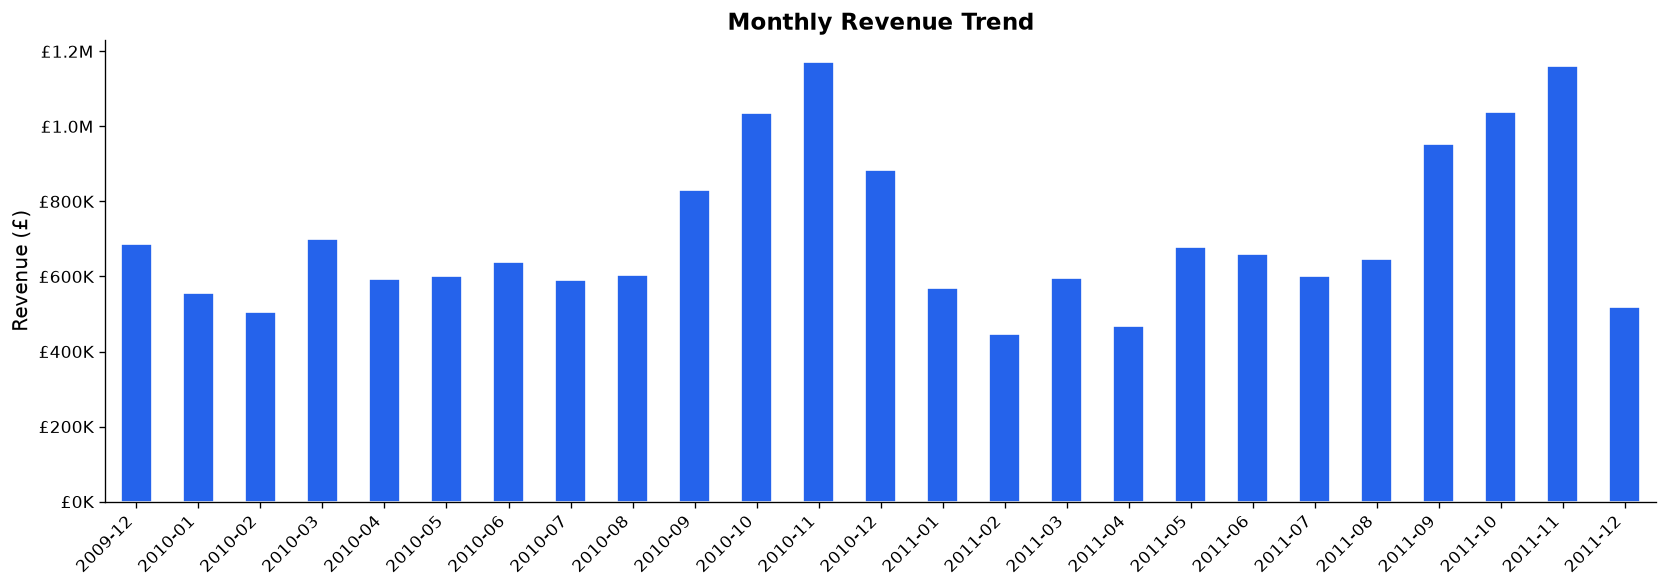

In [4]:
monthly_rev = df.groupby('YearMonth')['Revenue'].sum()

fig, ax = plt.subplots(figsize=(14, 5))
monthly_rev.plot(kind='bar', color=palette[0], edgecolor='white', ax=ax)
ax.set_title('Monthly Revenue Trend', fontweight='bold')
ax.set_ylabel('Revenue (£)')
ax.set_xlabel('')
ax.set_xticklabels([str(p) for p in monthly_rev.index], rotation=45, ha='right')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'£{x/1e6:.1f}M' if x >= 1e6 else f'£{x/1e3:.0f}K'))
plt.tight_layout()
plt.show()

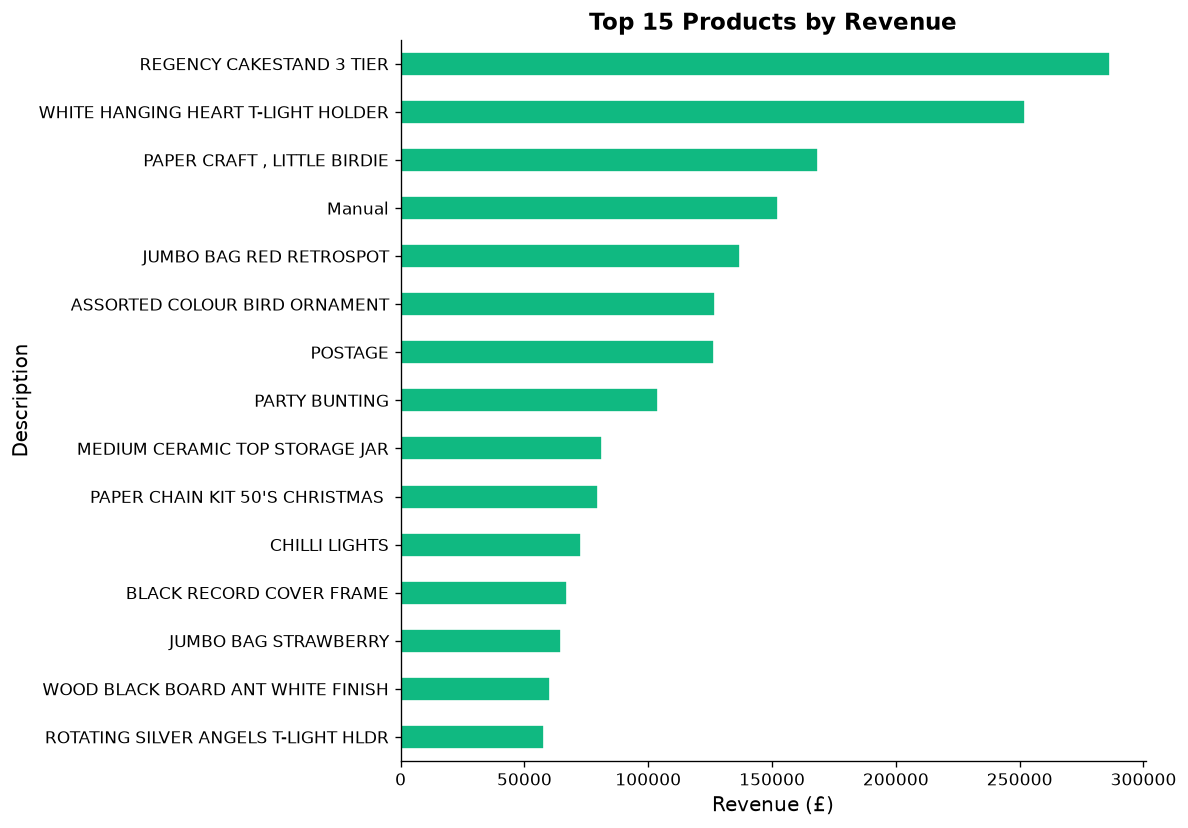

In [5]:
top_products = (
    df.groupby('Description')['Revenue']
    .sum()
    .nlargest(15)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 7))
top_products.plot(kind='barh', color=palette[1], edgecolor='white', ax=ax)
ax.set_title('Top 15 Products by Revenue', fontweight='bold')
ax.set_xlabel('Revenue (£)')
plt.tight_layout()
plt.show()

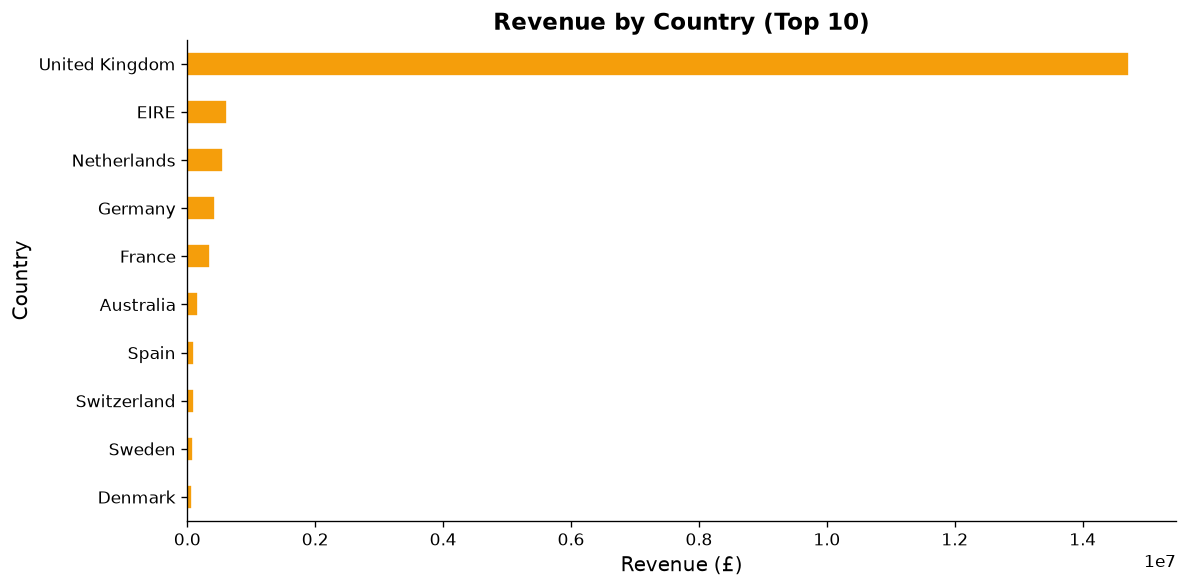

In [6]:
country_rev = df.groupby('Country')['Revenue'].sum().nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
country_rev.plot(kind='barh', color=palette[2], edgecolor='white', ax=ax)
ax.set_title('Revenue by Country (Top 10)', fontweight='bold')
ax.set_xlabel('Revenue (£)')
plt.tight_layout()
plt.show()

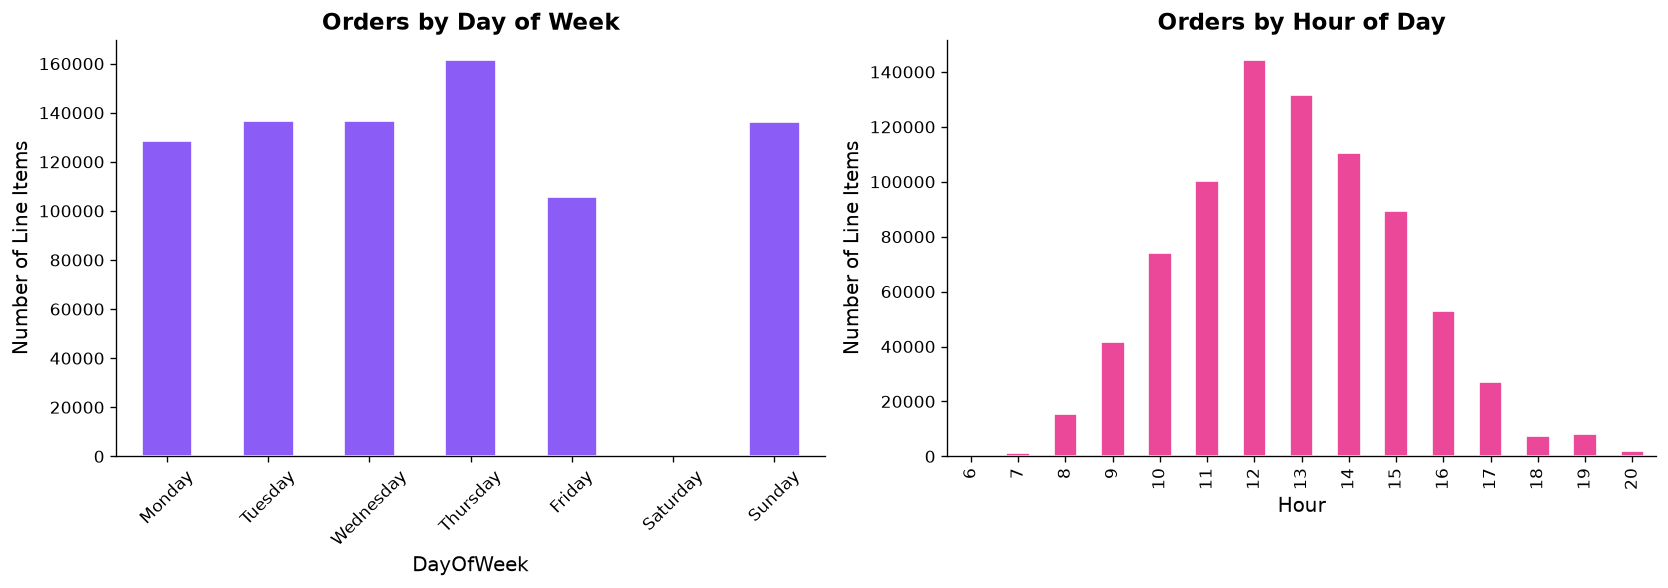

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['DayOfWeek'].value_counts().reindex(day_order).plot(
    kind='bar', color=palette[4], edgecolor='white', ax=axes[0]
)
axes[0].set_title('Orders by Day of Week', fontweight='bold')
axes[0].set_ylabel('Number of Line Items')
axes[0].tick_params(axis='x', rotation=45)

df['Hour'].value_counts().sort_index().plot(
    kind='bar', color=palette[5], edgecolor='white', ax=axes[1]
)
axes[1].set_title('Orders by Hour of Day', fontweight='bold')
axes[1].set_ylabel('Number of Line Items')

plt.tight_layout()
plt.show()

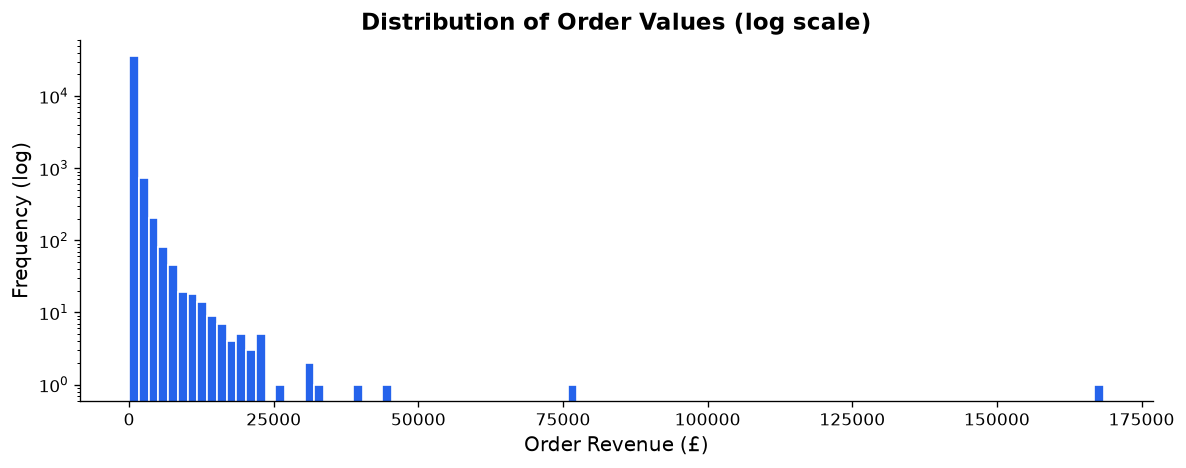

Median order value: £305.25
Mean order value:   £479.95
95th percentile:    £1253.78


In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
order_rev = df.groupby('Invoice')['Revenue'].sum()
ax.hist(order_rev, bins=100, color=palette[0], edgecolor='white', log=True)
ax.set_title('Distribution of Order Values (log scale)', fontweight='bold')
ax.set_xlabel('Order Revenue (£)')
ax.set_ylabel('Frequency (log)')
plt.tight_layout()
plt.show()

print(f"Median order value: £{order_rev.median():.2f}")
print(f"Mean order value:   £{order_rev.mean():.2f}")
print(f"95th percentile:    £{order_rev.quantile(0.95):.2f}")

<a id="4"></a>
## 4. RFM Segmentation & K-Means Clustering

Knowing what sells is only half the picture. I also wanted to understand *who* is buying. To do that, I used **RFM**, a classic framework that describes each customer with three numbers:
- **Recency:** Days since last purchase
- **Frequency:** Total number of orders
- **Monetary:** Total revenue

I calculated these for every customer, standardized them, and then let K-Means clustering find the natural customer segments instead of drawing the boundaries myself.

In [9]:
snapshot_date = df['InvoiceDate'].max() + timedelta(days=1)

rfm = df.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency = ('Invoice',     'nunique'),
    Monetary  = ('Revenue',     'sum')
).reset_index()

monetary_cap = rfm['Monetary'].quantile(0.99)
rfm = rfm[rfm['Monetary'] <= monetary_cap]

print(f"RFM table: {len(rfm):,} customers")
rfm.describe().round(1)

RFM table: 5,819 customers


,Customer ID,Recency,Frequency,Monetary
count,5819.0,5819.0,5819.0,5819.0
mean,15316.9,202.9,5.5,2075.3
std,1714.7,209.5,7.4,3366.5
min,12347.0,1.0,1.0,3.0
25%,13835.5,26.0,1.0,344.7
50%,15318.0,99.0,3.0,876.0
75%,16799.5,381.0,7.0,2228.2
max,18287.0,739.0,122.0,29532.4


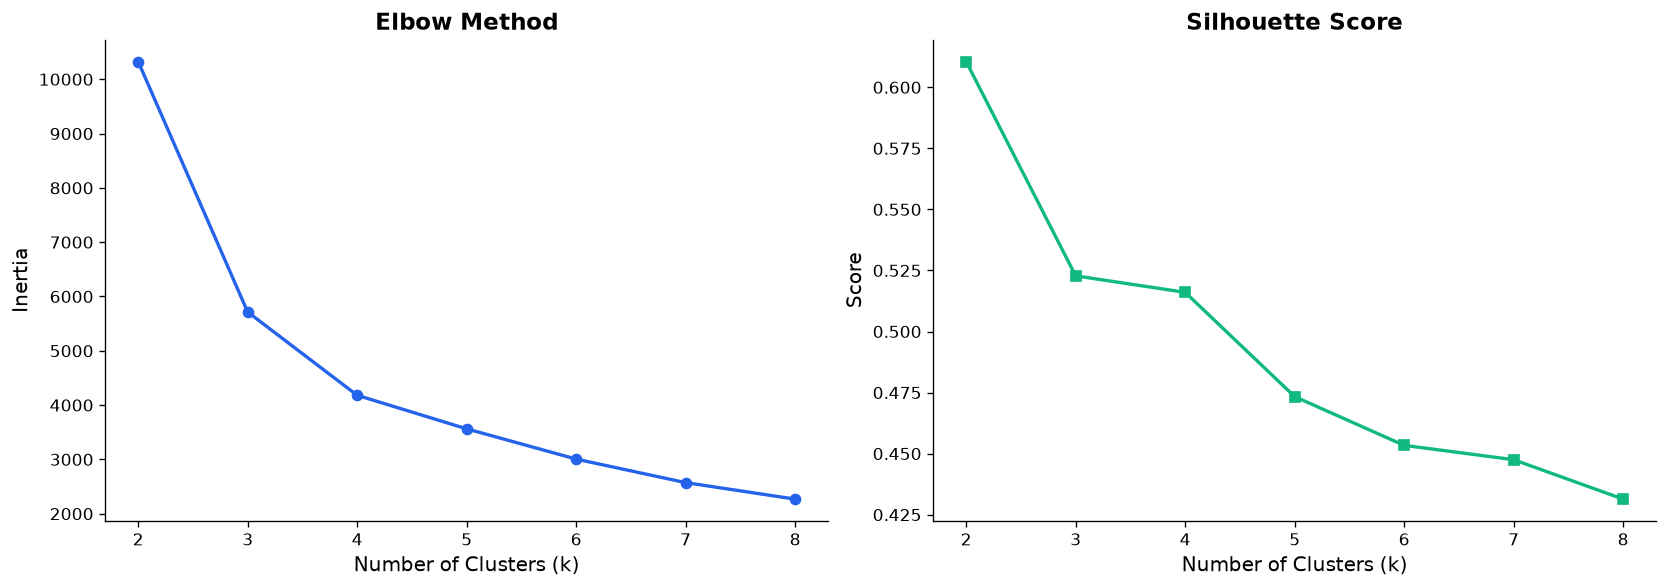

✅ Optimal k by silhouette: 2  (score = 0.611)


In [10]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])

inertias = []
sil_scores = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, 'o-', color=palette[0], linewidth=2)
axes[0].set_title('Elbow Method', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, sil_scores, 's-', color=palette[1], linewidth=2)
axes[1].set_title('Silhouette Score', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

best_k = K_range[np.argmax(sil_scores)]
print(f"✅ Optimal k by silhouette: {best_k}  (score = {max(sil_scores):.3f})")

In [11]:
km_final = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = km_final.fit_predict(rfm_scaled)

cluster_summary = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(1)

cluster_z = (cluster_summary - cluster_summary.mean()) / cluster_summary.std()
cluster_score = cluster_z['Frequency'] + cluster_z['Monetary'] - cluster_z['Recency']

segment_names = ['🏆 Champions', '💎 Loyal', '⚠️ At Risk', '💤 Hibernating']
ranked_clusters = cluster_score.sort_values(ascending=False).index
labels = dict(zip(ranked_clusters, segment_names))

rfm['Segment'] = rfm['Cluster'].map(labels)

cluster_summary['Segment'] = cluster_summary.index.map(labels)
cluster_summary['Count'] = rfm.groupby('Cluster').size().values
cluster_summary

,Recency,Frequency,Monetary,Segment,Count
Cluster,,,,,
0,84.5,3.7,1137.8,⚠️ At Risk,2940
1,475.7,2.0,652.3,💤 Hibernating,1862
2,48.7,13.7,5519.0,💎 Loyal,830
3,31.4,32.8,15699.3,🏆 Champions,187


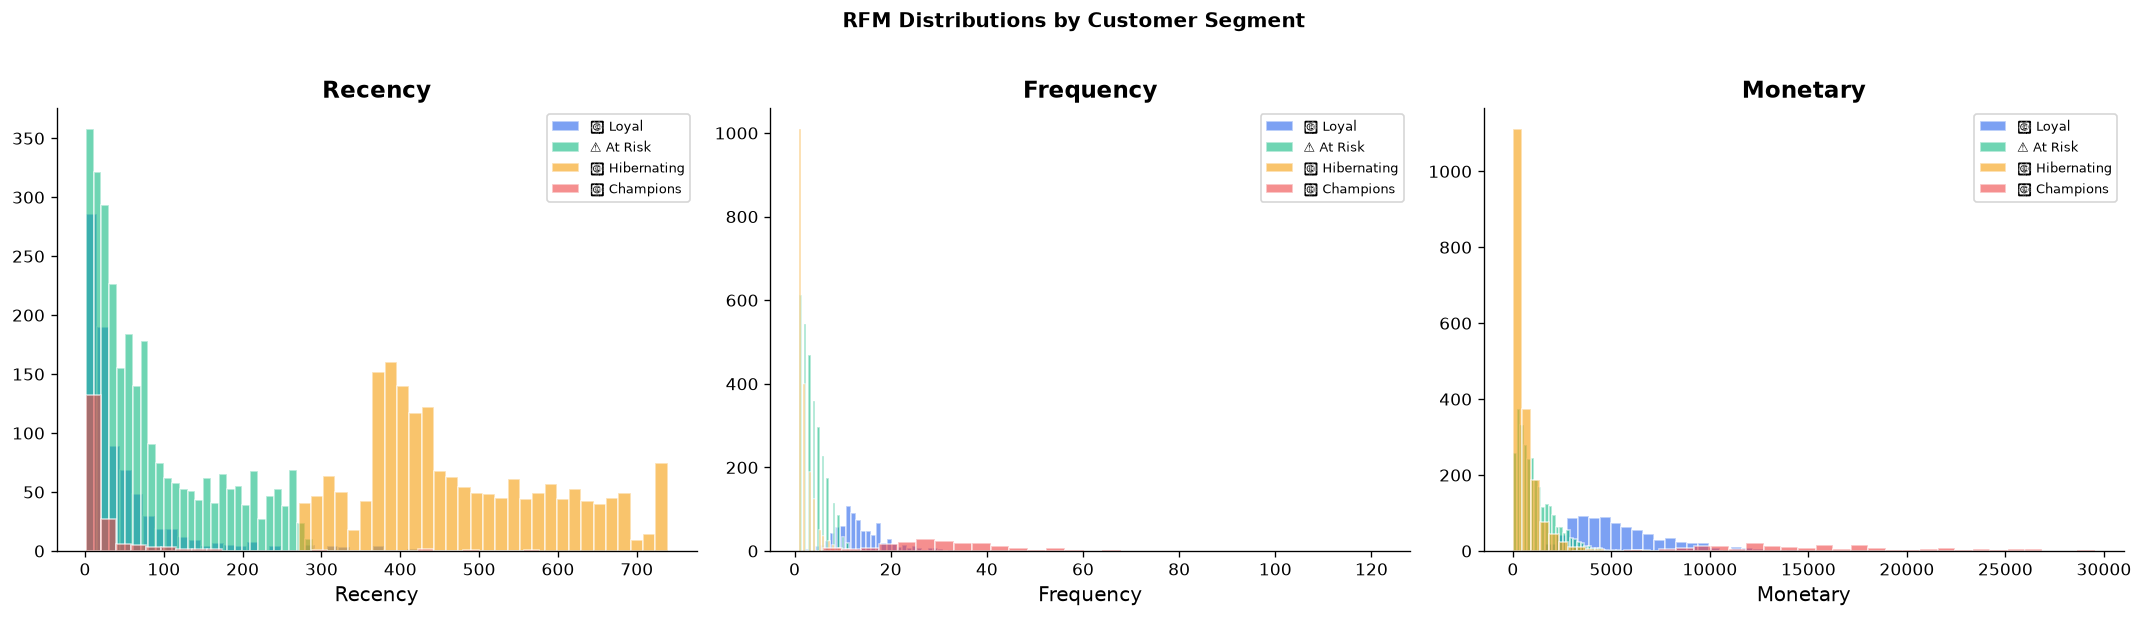

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    for seg in rfm['Segment'].unique():
        subset = rfm[rfm['Segment'] == seg]
        axes[i].hist(subset[col], bins=30, alpha=0.6, label=seg, edgecolor='white')
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].legend(fontsize=8)

plt.suptitle('RFM Distributions by Customer Segment', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

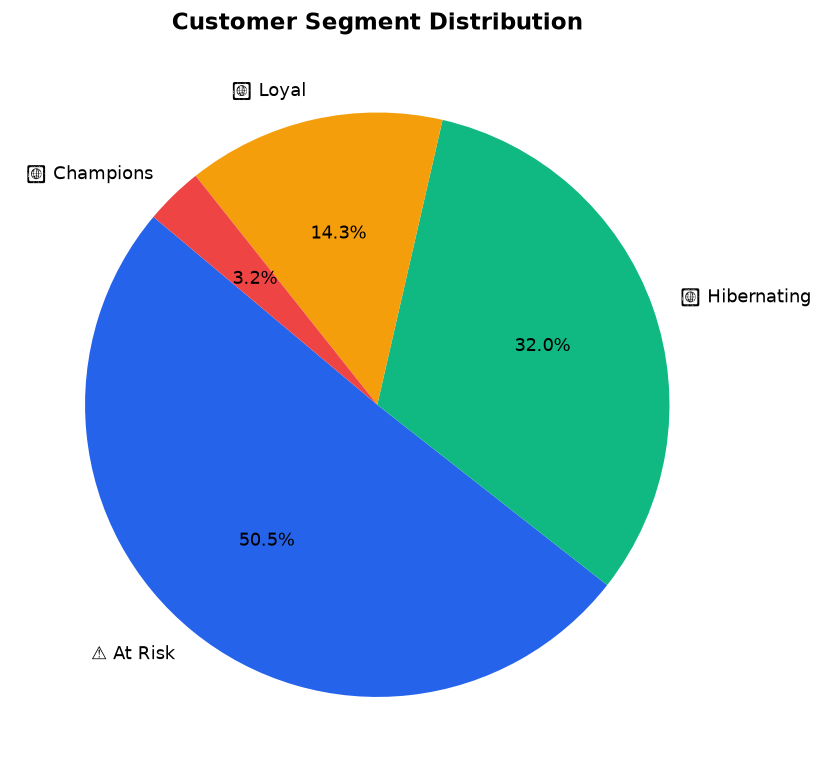

In [13]:
seg_counts = rfm['Segment'].value_counts()

fig, ax = plt.subplots(figsize=(7, 7))
colors_pie = [palette[i % len(palette)] for i in range(len(seg_counts))]
wedges, texts, autotexts = ax.pie(
    seg_counts, labels=seg_counts.index, autopct='%1.1f%%',
    colors=colors_pie, startangle=140, textprops={'fontsize': 11}
)
ax.set_title('Customer Segment Distribution', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

<a id="5"></a>
## 5. Cohort Retention Analysis

The segments showed me who the customers are, but I also wanted to know whether they stick around. To find out, I grouped customers into cohorts by the **month of their first purchase** and tracked what percentage of each cohort came back in the months that followed.

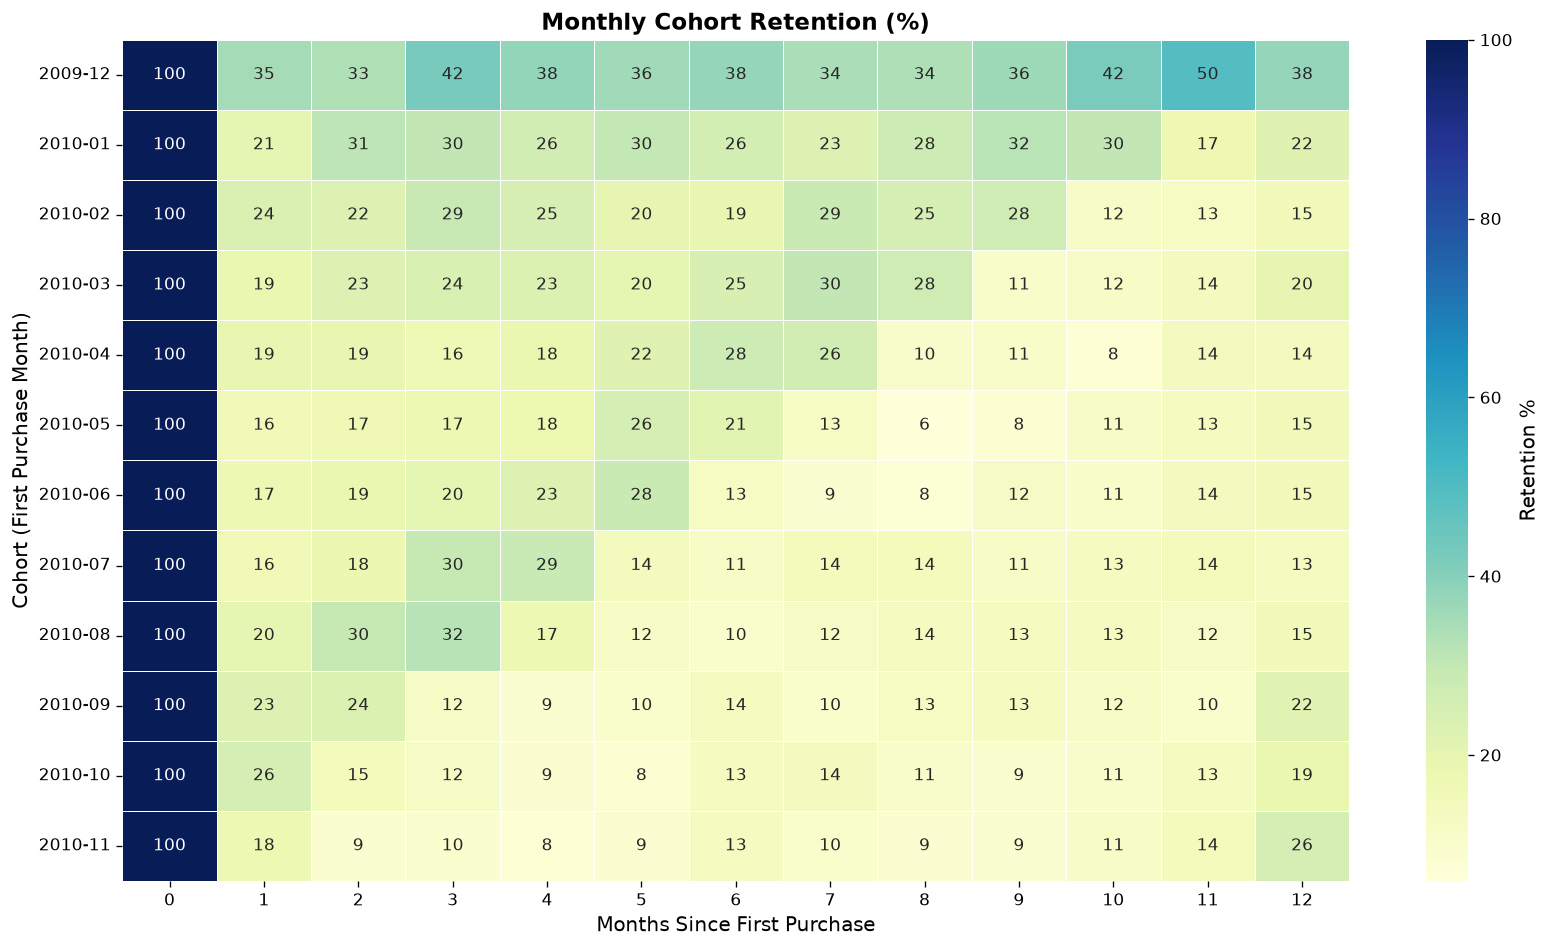

In [14]:
df['OrderMonth'] = df['InvoiceDate'].dt.to_period('M')
cohort_month = df.groupby('Customer ID')['OrderMonth'].min().rename('CohortMonth')
df = df.merge(cohort_month, on='Customer ID')

df['CohortIndex'] = (
    (df['OrderMonth'].dt.year - df['CohortMonth'].dt.year) * 12
    + (df['OrderMonth'].dt.month - df['CohortMonth'].dt.month)
)

cohort_data = (
    df.groupby(['CohortMonth', 'CohortIndex'])['Customer ID']
    .nunique()
    .reset_index()
    .rename(columns={'Customer ID': 'Customers'})
)

cohort_pivot = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='Customers')

cohort_sizes = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_sizes, axis=0).round(3) * 100

retention_display = retention.iloc[:12, :13]

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(
    retention_display,
    annot=True, fmt='.0f', cmap='YlGnBu',
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Retention %'},
    ax=ax
)
ax.set_title('Monthly Cohort Retention (%)', fontweight='bold', fontsize=14)
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Cohort (First Purchase Month)')
ax.set_yticklabels([str(p) for p in retention_display.index], rotation=0)
plt.tight_layout()
plt.show()

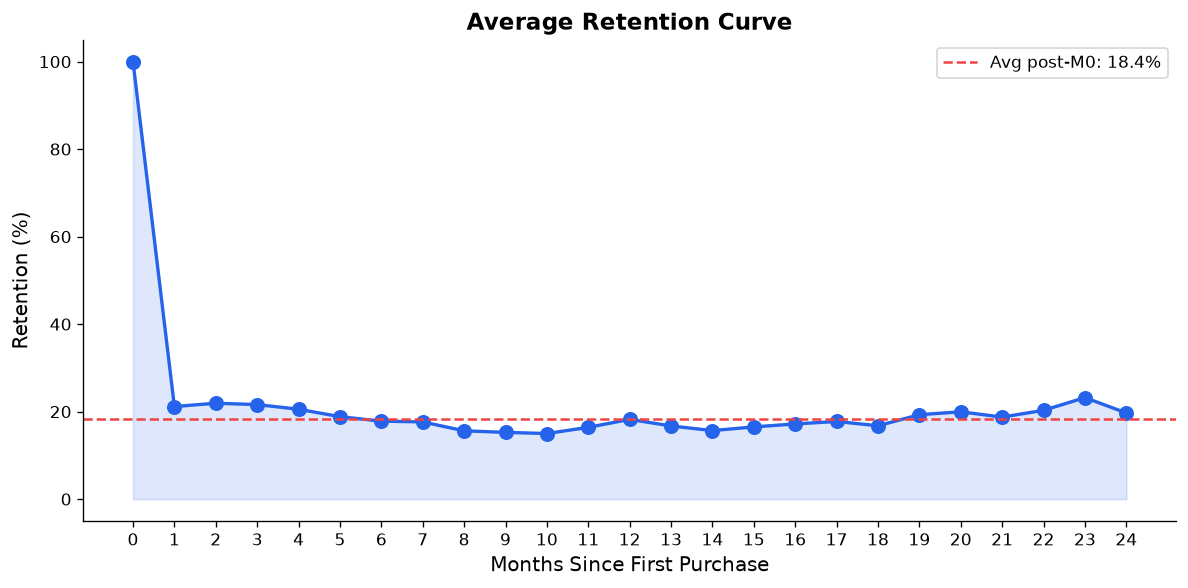

In [15]:
avg_retention = retention.mean(axis=0).dropna()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(avg_retention.index, avg_retention.values, 'o-', color=palette[0], linewidth=2, markersize=8)
ax.fill_between(avg_retention.index, avg_retention.values, alpha=0.15, color=palette[0])
ax.set_title('Average Retention Curve', fontweight='bold')
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Retention (%)')
ax.set_xticks(avg_retention.index)
ax.axhline(y=avg_retention.iloc[1:].mean(), color=palette[3], linestyle='--', label=f'Avg post-M0: {avg_retention.iloc[1:].mean():.1f}%')
ax.legend()
plt.tight_layout()
plt.show()

<a id="6"></a>
## 6. Marketing Channel Attribution

Next, I turned to the question every marketing team asks: where should the budget go? I compared the acquisition channels on:
- Revenue per channel
- Conversion rate (customers with repeat purchases)
- Average order value
- Revenue per customer

> **Note:** Acquisition channels were engineered (simulated) because the UCI dataset does not include marketing source data. The channel distribution follows typical e-commerce benchmarks.

In [16]:
ch_col = 'AcquisitionChannel'

channel_summary = df.groupby(ch_col).agg(
    Total_Revenue    = ('Revenue',      'sum'),
    Total_Orders     = ('Invoice',      'nunique'),
    Unique_Customers = ('Customer ID',  'nunique'),
    Avg_Order_Value  = ('Revenue',      'mean'),
).reset_index()

channel_summary['Revenue_per_Customer'] = (
    channel_summary['Total_Revenue'] / channel_summary['Unique_Customers']
).round(2)

repeat_customers = (
    df.groupby([ch_col, 'Customer ID'])['Invoice']
    .nunique()
    .reset_index()
)
repeat_customers['IsRepeat'] = repeat_customers['Invoice'] > 1

repeat_rate = (
    repeat_customers.groupby(ch_col)['IsRepeat']
    .mean()
    .reset_index()
    .rename(columns={'IsRepeat': 'Repeat_Rate'})
)

channel_summary = channel_summary.merge(repeat_rate, on=ch_col)
channel_summary['Repeat_Rate'] = (channel_summary['Repeat_Rate'] * 100).round(1)

channel_summary.sort_values('Total_Revenue', ascending=False)

,AcquisitionChannel,Total_Revenue,Total_Orders,Unique_Customers,Avg_Order_Value,Revenue_per_Customer,Repeat_Rate
2,Organic Search,5987751.689,11467,1797,23.167034,3332.08,73.2
3,Paid Social,3947335.200,8944,1439,19.666173,2743.11,73.0
1,Email,3806836.654,7121,1191,25.186153,3196.34,70.1
0,Direct,2358500.500,5779,876,19.971383,2692.35,72.9
4,Referral,1643005.135,3658,575,21.301765,2857.40,72.2


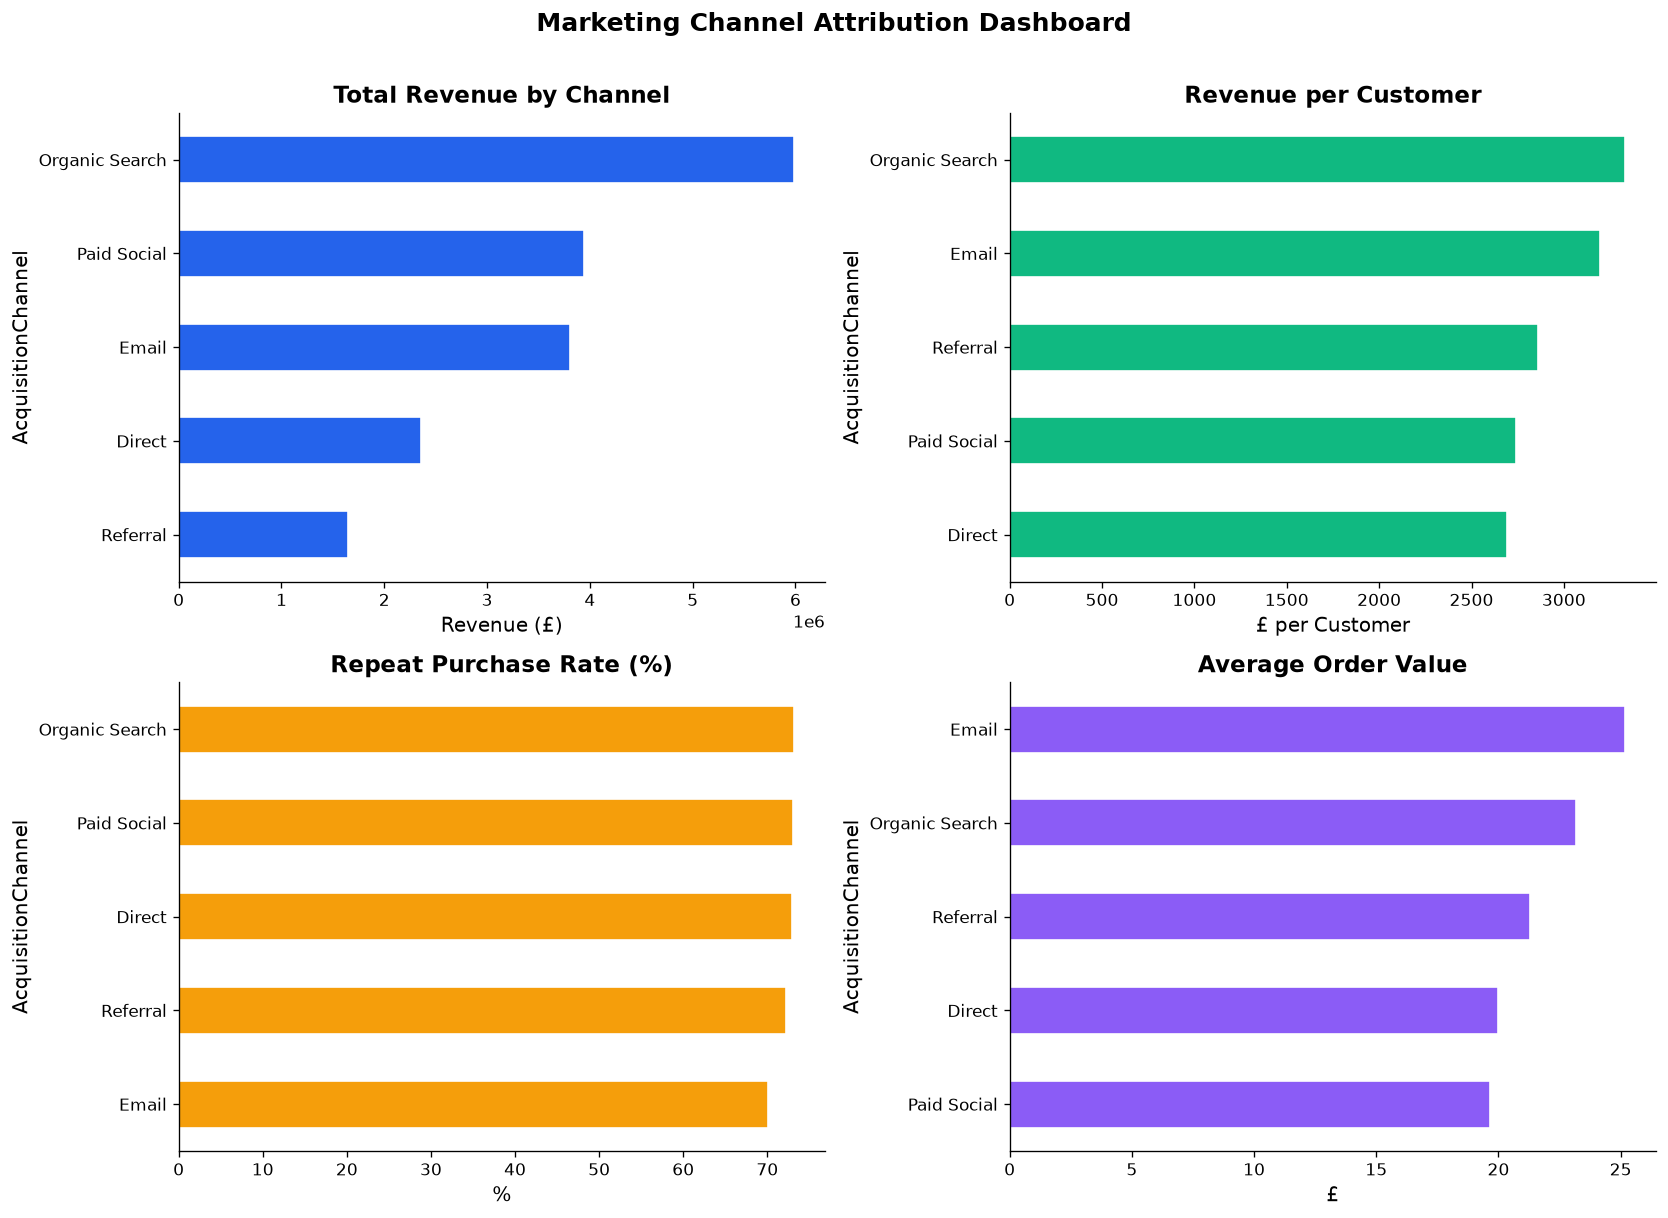

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

channel_summary.sort_values('Total_Revenue').plot(
    kind='barh', x=ch_col, y='Total_Revenue',
    color=palette[0], edgecolor='white', ax=axes[0, 0], legend=False
)
axes[0, 0].set_title('Total Revenue by Channel', fontweight='bold')
axes[0, 0].set_xlabel('Revenue (£)')

channel_summary.sort_values('Revenue_per_Customer').plot(
    kind='barh', x=ch_col, y='Revenue_per_Customer',
    color=palette[1], edgecolor='white', ax=axes[0, 1], legend=False
)
axes[0, 1].set_title('Revenue per Customer', fontweight='bold')
axes[0, 1].set_xlabel('£ per Customer')

channel_summary.sort_values('Repeat_Rate').plot(
    kind='barh', x=ch_col, y='Repeat_Rate',
    color=palette[2], edgecolor='white', ax=axes[1, 0], legend=False
)
axes[1, 0].set_title('Repeat Purchase Rate (%)', fontweight='bold')
axes[1, 0].set_xlabel('%')

channel_summary.sort_values('Avg_Order_Value').plot(
    kind='barh', x=ch_col, y='Avg_Order_Value',
    color=palette[4], edgecolor='white', ax=axes[1, 1], legend=False
)
axes[1, 1].set_title('Average Order Value', fontweight='bold')
axes[1, 1].set_xlabel('£')

plt.suptitle('Marketing Channel Attribution Dashboard', fontweight='bold', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

<a id="7"></a>
## 7. Campaign A/B Test Analysis

Each customer was assigned one of two campaign variants (**A** or **B**) at acquisition. I wanted to know whether one variant genuinely performed better or whether any difference was just noise. Here is how I tested it:
- **Conversion metric:** Average revenue per customer
- **Statistical test:** Welch's t-test for independent samples
- **Effect size:** Cohen's d
- **Confidence intervals** to show the range of plausible differences

> **Note:** Campaign variants were engineered (simulated 50/50 split) because the UCI dataset does not include campaign data.

In [18]:
variant_rev = df.groupby(['Customer ID', 'CampaignVariant']).agg(
    Total_Revenue = ('Revenue', 'sum'),
    Order_Count   = ('Invoice', 'nunique')
).reset_index()

group_a = variant_rev[variant_rev['CampaignVariant'] == 'A']['Total_Revenue']
group_b = variant_rev[variant_rev['CampaignVariant'] == 'B']['Total_Revenue']

print(f"Variant A: n={len(group_a):,}, mean=£{group_a.mean():.2f}, median=£{group_a.median():.2f}")
print(f"Variant B: n={len(group_b):,}, mean=£{group_b.mean():.2f}, median=£{group_b.median():.2f}")

Variant A: n=2,994, mean=£2870.66, median=£919.06
Variant B: n=2,884, mean=£3172.22, median=£872.44


In [19]:
t_stat, p_value = stats.ttest_ind(group_a, group_b, equal_var=False)

pooled_std = np.sqrt((group_a.std()**2 + group_b.std()**2) / 2)
cohens_d = (group_a.mean() - group_b.mean()) / pooled_std

diff_mean = group_a.mean() - group_b.mean()
se_diff = np.sqrt(group_a.var()/len(group_a) + group_b.var()/len(group_b))
ci_95 = (diff_mean - 1.96 * se_diff, diff_mean + 1.96 * se_diff)

print("=" * 55)
print("          A/B TEST RESULTS")
print("=" * 55)
print(f"  Mean difference (A - B): £{diff_mean:.2f}")
print(f"  t-statistic:             {t_stat:.4f}")
print(f"  p-value:                 {p_value:.4f}")
print(f"  Cohen's d:               {cohens_d:.4f}")
print(f"  95% CI for difference:   (£{ci_95[0]:.2f}, £{ci_95[1]:.2f})")
print(f"  Significant at α=0.05?   {'Yes ✅' if p_value < 0.05 else 'No ❌'}")
print("=" * 55)

          A/B TEST RESULTS
  Mean difference (A - B): £-301.56
  t-statistic:             -0.7831
  p-value:                 0.4336
  Cohen's d:               -0.0204
  95% CI for difference:   (£-1056.30, £453.18)
  Significant at α=0.05?   No ❌


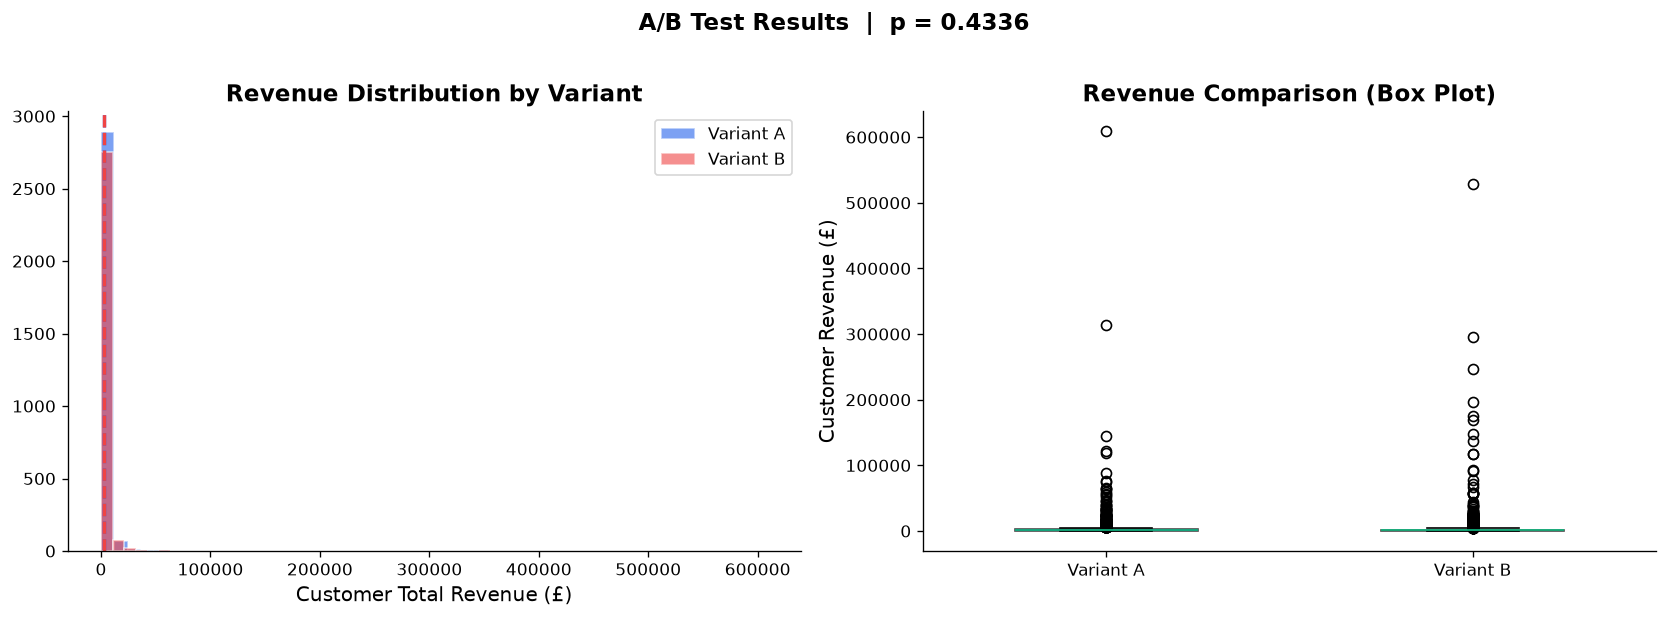

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(group_a, bins=50, alpha=0.6, color=palette[0], label='Variant A', edgecolor='white')
axes[0].hist(group_b, bins=50, alpha=0.6, color=palette[3], label='Variant B', edgecolor='white')
axes[0].axvline(group_a.mean(), color=palette[0], linestyle='--', linewidth=2)
axes[0].axvline(group_b.mean(), color=palette[3], linestyle='--', linewidth=2)
axes[0].set_title('Revenue Distribution by Variant', fontweight='bold')
axes[0].set_xlabel('Customer Total Revenue (£)')
axes[0].legend()

bp = axes[1].boxplot([group_a, group_b], tick_labels=['Variant A', 'Variant B'],
                      patch_artist=True, widths=0.5)
bp['boxes'][0].set_facecolor(palette[0])
bp['boxes'][1].set_facecolor(palette[3])
for box in bp['boxes']:
    box.set_alpha(0.7)
axes[1].set_title('Revenue Comparison (Box Plot)', fontweight='bold')
axes[1].set_ylabel('Customer Revenue (£)')

plt.suptitle(f'A/B Test Results  |  p = {p_value:.4f}', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

<a id="8"></a>
## 8. Customer Lifetime Value (CLV) Prediction

Up to this point I had been looking backward. For the final step, I wanted to look forward: which customers are likely to be worth the most in the future? I built a regression-based CLV model that uses RFM features to predict future revenue. My approach:

1. I split the 2-year dataset at **January 2011** (midpoint)
2. I used the first ~13 months (Dec 2009 – Dec 2010) to compute RFM features
3. I used the actual revenue from the remaining ~12 months (Jan 2011 – Dec 2011) as the target
4. I trained a Ridge regression model

> **Alternative approaches:** BG/NBD + Gamma-Gamma (via the `lifetimes` library) is ideal for contractual/subscription contexts. I chose the regression approach here because it is more flexible for portfolio demonstration.

In [21]:
midpoint = pd.Timestamp('2011-01-01')

cal  = df[df['InvoiceDate'] < midpoint]
hold = df[df['InvoiceDate'] >= midpoint]

print(f"Calibration period: {cal['InvoiceDate'].min().date()} to {cal['InvoiceDate'].max().date()}  ({len(cal):,} rows)")
print(f"Holdout period:     {hold['InvoiceDate'].min().date()} to {hold['InvoiceDate'].max().date()}  ({len(hold):,} rows)")

Calibration period: 2009-12-01 to 2010-12-23  (433,821 rows)
Holdout period:     2011-01-04 to 2011-12-09  (371,728 rows)


In [22]:
cal_snapshot = cal['InvoiceDate'].max() + timedelta(days=1)

rfm_cal = cal.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (cal_snapshot - x.max()).days),
    Frequency = ('Invoice',     'nunique'),
    Monetary  = ('Revenue',     'sum'),
    Tenure    = ('InvoiceDate', lambda x: (x.max() - x.min()).days),
    AvgOrderValue = ('Revenue', 'mean'),
).reset_index()

holdout_rev = hold.groupby('Customer ID')['Revenue'].sum().rename('Future_Revenue')

clv_df = rfm_cal.merge(holdout_rev, on='Customer ID', how='left')
clv_df['Future_Revenue'] = clv_df['Future_Revenue'].fillna(0)

for col in ['Monetary', 'Future_Revenue']:
    cap = clv_df[col].quantile(0.99)
    clv_df[col] = clv_df[col].clip(upper=cap)

print(f"CLV dataset: {len(clv_df):,} customers")
clv_df.head()

CLV dataset: 4,342 customers


,Customer ID,Recency,Frequency,Monetary,Tenure,AvgOrderValue,Future_Revenue
0,12346.0,179,11,372.86,196,11.298788,16150.2452
1,12347.0,17,2,2035.11,37,19.952059,3598.2100
2,12348.0,7,2,1114.96,80,30.134054,904.4400
3,12349.0,57,3,2671.14,181,26.187647,1757.5500
4,12351.0,25,1,300.93,0,14.330000,0.0000


In [23]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, r2_score

features = ['Recency', 'Frequency', 'Monetary', 'Tenure', 'AvgOrderValue']
X = clv_df[features]
y = clv_df['Future_Revenue']

scaler_clv = StandardScaler()
X_scaled = scaler_clv.fit_transform(X)

model = Ridge(alpha=10)
cv_scores = cross_val_score(model, X_scaled, y, cv=5, scoring='r2')
print(f"Cross-validated R²: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

model.fit(X_scaled, y)
clv_df['Predicted_CLV'] = model.predict(X_scaled)
clv_df['Predicted_CLV'] = clv_df['Predicted_CLV'].clip(lower=0)

mae = mean_absolute_error(y, clv_df['Predicted_CLV'])
r2  = r2_score(y, clv_df['Predicted_CLV'])
print(f"MAE:  £{mae:.2f}")
print(f"R²:   {r2:.3f}")

Cross-validated R²: 0.593 ± 0.021
MAE:  £761.71
R²:   0.602


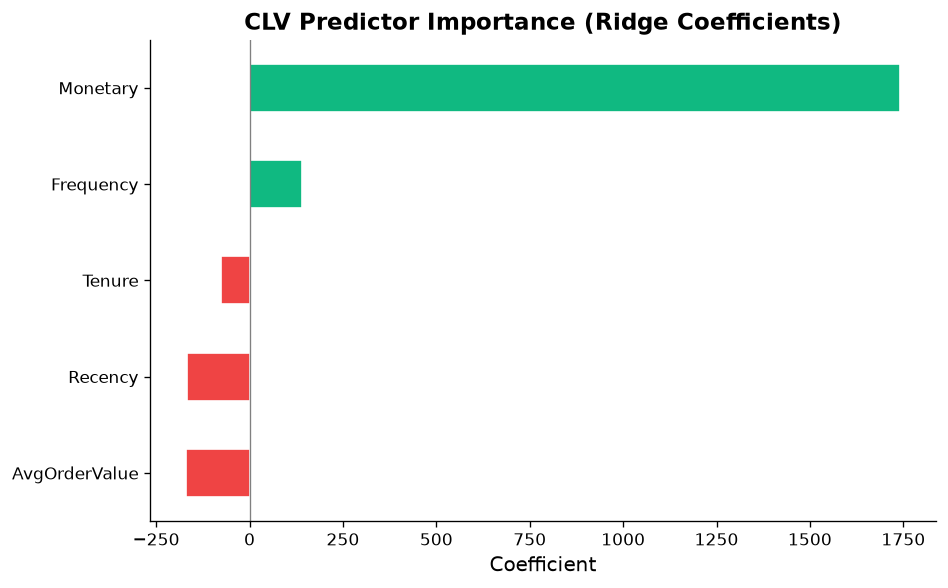

In [24]:
importance = pd.Series(model.coef_, index=features).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot(kind='barh', color=[palette[3] if v < 0 else palette[1] for v in importance], ax=ax, edgecolor='white')
ax.set_title('CLV Predictor Importance (Ridge Coefficients)', fontweight='bold')
ax.set_xlabel('Coefficient')
ax.axvline(0, color='gray', linewidth=0.8)
plt.tight_layout()
plt.show()

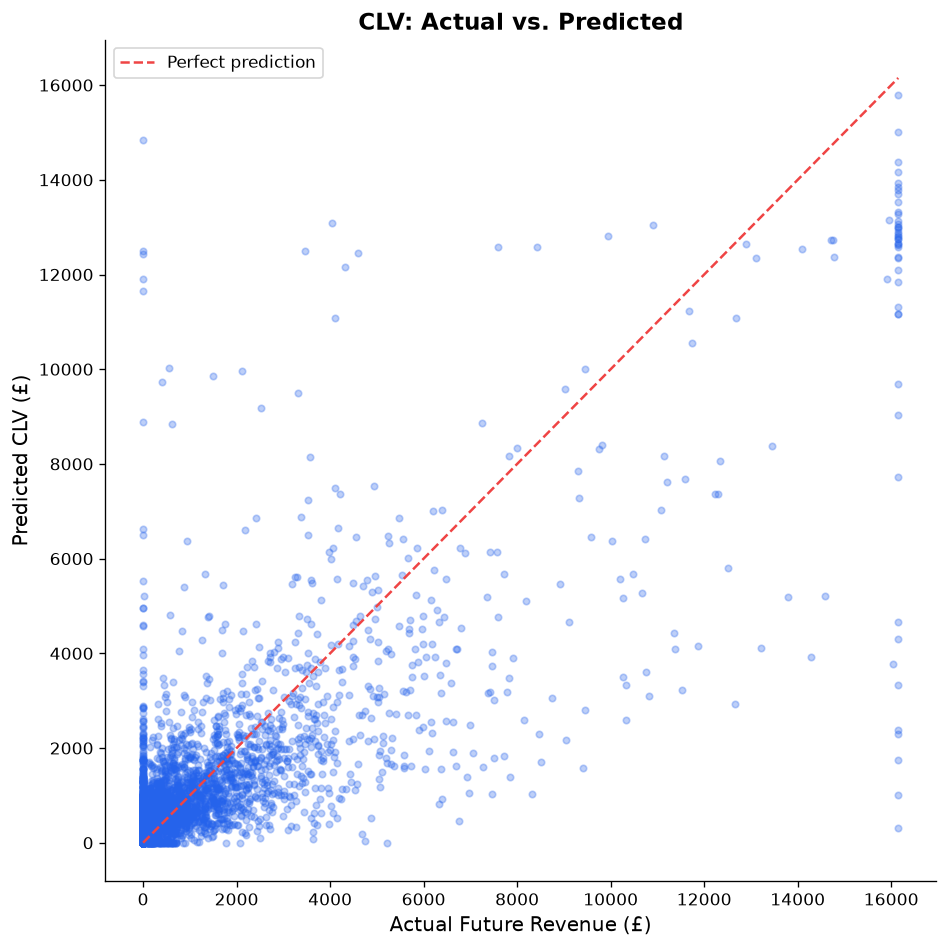

In [25]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y, clv_df['Predicted_CLV'], alpha=0.3, s=15, color=palette[0])
lims = [0, max(y.max(), clv_df['Predicted_CLV'].max())]
ax.plot(lims, lims, '--', color=palette[3], linewidth=1.5, label='Perfect prediction')
ax.set_title('CLV: Actual vs. Predicted', fontweight='bold')
ax.set_xlabel('Actual Future Revenue (£)')
ax.set_ylabel('Predicted CLV (£)')
ax.legend()
plt.tight_layout()
plt.show()

In [26]:
clv_df['CLV_Tier'] = pd.qcut(clv_df['Predicted_CLV'], q=4, labels=['Low', 'Medium', 'High', 'VIP'])

tier_summary = clv_df.groupby('CLV_Tier', observed=True).agg(
    Count         = ('Customer ID', 'count'),
    Avg_Pred_CLV  = ('Predicted_CLV', 'mean'),
    Avg_Actual    = ('Future_Revenue', 'mean'),
    Avg_Frequency = ('Frequency', 'mean'),
    Avg_Monetary  = ('Monetary', 'mean'),
).round(2)

print("CLV Tier Summary:")
tier_summary

CLV Tier Summary:


,Count,Avg_Pred_CLV,Avg_Actual,Avg_Frequency,Avg_Monetary
CLV_Tier,,,,,
Low,1086,122.20,177.44,1.35,267.25
Medium,1085,443.24,319.69,1.92,456.46
High,1085,840.03,731.11,3.68,1163.47
VIP,1086,3160.46,3302.82,11.32,5168.80


<a id="9"></a>
## 9. Executive Summary & Recommendations

After working through every stage of the analysis, here is what the data told me and what I would recommend. The segmentation, retention and CLV findings come from real customer behaviour. The channel and A/B sections use simulated labels, so I treat them as demonstrations of method rather than business conclusions.

### Key Findings

| Analysis | Insight |
|:---------|:--------|
| **RFM Segmentation** | K-Means split 5,819 customers into 4 segments. **Champions** (187 customers, 3.2%) and **Loyal** customers (830, 14.3%) make up just **17.5% of the customer base but generate 62.2% of revenue**. The largest group is **At Risk** (2,940 customers, 50.5%): they have bought about 4 times, but their last purchase was almost 3 months ago. **Hibernating** customers (1,862, 32.0%) have not bought in over a year and contribute only 10.1% of revenue. The silhouette score favoured k = 2, but I kept k = 4 because the extra segments are more useful for targeting. |
| **Cohort Retention** | The biggest drop happens right after the first purchase: on average only **~21% of customers buy again in Month 1**. Most customers do come back eventually (**72.4% place a second order**), but slowly: the median gap between the first and second order is **55 days**, and only 23.6% reorder within 30 days. Repeat buyers are worth far more, averaging **£4,036 in revenue versus £350** for one-time buyers. |
| **Sales Timing** | Sales are highly seasonal: **September to December brings in 46.8% of annual revenue**, peaking in November (13.2%). Orders are concentrated on weekdays (Thursday is the busiest day, Saturday has almost none) and **78.7% are placed between 10:00 and 15:59**, a business-hours pattern that suggests many customers are business buyers. |
| **Channel Attribution** | Organic Search (£3,332) and Email (£3,196) show the highest revenue per customer, while repeat rates are almost identical across channels (70–73%). Because channels were **randomly assigned**, these differences reflect chance rather than real channel performance. The section demonstrates the attribution framework, not a budget conclusion. |
| **A/B Test** | There is **no significant difference** between variants A and B (p = 0.43, Cohen's d = −0.02, 95% CI for the difference: −£1,056 to £453). This is the expected result, since the variants were also randomly assigned. |
| **CLV Prediction** | The Ridge model explains about **60% of the variation** in next-year revenue (cross-validated R² = 0.59, MAE = £762). **Past spend (Monetary)** is by far the strongest predictor. The **VIP tier (top 25%) generated 72.9% of actual next-year revenue**, averaging £3,303 per customer versus £177 for the lowest tier. |

### Strategic Recommendations

1. **Shorten the time to the second order.** 27.6% of customers never order again, and the rest take a median of 55 days to do so. Set up an automated post-purchase sequence: a thank-you and product suggestions based on the first order at day 7, a reorder reminder at day 30, and a small incentive at day 45, just before the typical 55-day gap. Track the share of new customers who reorder within 60 days (currently 38.2%) as the main KPI.

2. **Re-engage At-Risk customers before they go dormant.** This is the largest segment: 2,940 customers (50.5%) who have ordered about 4 times and spent £1,138 on average, but whose median time since last order is 57 days, more than twice the 25 days of Loyal customers. Trigger a personalised reminder when any customer passes 60 days without ordering, and add a time-limited offer only if they still have not ordered by day 90. To give a sense of scale: reactivating 10% of this group (294 customers) at their historical average spend would be worth roughly £335K.

3. **Protect and grow the top customers.** Champions and Loyal customers (1,017 people, 17.5%) generate 62.2% of revenue, and the VIP tier produced 72.9% of next-year revenue. Give the 187 Champions (average spend £15,699 across 33 orders) a dedicated account contact, and offer Loyal customers volume pricing or a loyalty tier to move them up. Flag any Champion who goes 30 days without ordering (three times their usual 10-day median) for a personal check-in. Re-score customers with the CLV model each quarter to spot rising VIPs early.

4. **Keep spending on Hibernating customers low.** 1,862 customers (32.0%) have not ordered in a median of 437 days and contribute only 10.1% of revenue. Send them one low-cost reactivation email ahead of the Q4 peak, and remove non-responders from paid retargeting and regular email sends to protect deliverability. Budget is better spent on At-Risk customers, who are far more likely to return.

5. **Plan campaigns around the Q4 peak and business hours.** With nearly half of revenue arriving between September and December, launch the seasonal range, win-back campaigns and stock planning in late August so customers are re-engaged before the peak. Schedule emails for Tuesday to Thursday mornings, ahead of the 10:00–15:59 ordering window, and avoid Saturday sends.

6. **Start tracking real acquisition channels before moving budget.** Add UTM tags to every campaign link, record each customer's first-touch channel at sign-up, and rerun the attribution analysis once 6 months of real data are available. Budget should only be shifted between channels after that.

7. **Design future A/B tests to give a clear answer.** Revenue per customer is heavily skewed (mean £2,871 vs median £919 for Variant A), which is why the confidence interval in this test was so wide. Use a less noisy primary metric such as "reordered within 60 days", decide the sample size before the test starts, and test bold differences (offers, subject lines, landing pages) rather than minor copy changes.

---

*I built this analysis as a portfolio project to demonstrate end-to-end marketing analytics, from segmentation and retention modeling to statistical testing and predictive modeling.*
*Dataset: UCI Online Retail II (Daqing Chen, 2019). Available from the UCI Machine Learning Repository.*